# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

In [1]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [2]:
import os
os.environ["USE_TF"] = "0"

In [12]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cpu


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Image size: (2079, 2571)
Image mode: RGB


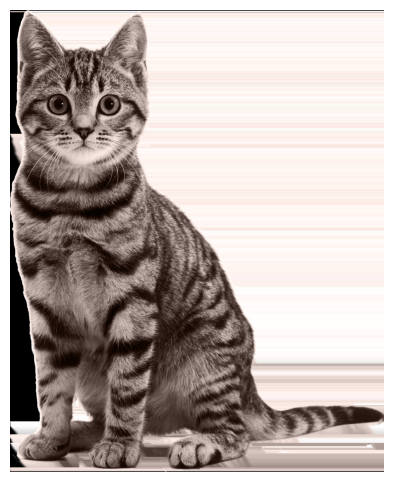

In [5]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "cat_png.png"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [6]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9880
a photo of a dog                   : 0.0063
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0006
a photo of a person                : 0.0051


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [12]:
# STUDENT TASK
import torch
from transformers import CLIPProcessor, CLIPModel

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

def classify_image(image, classes):
    prompts = [f"a photo of a {c}" for c in classes]
    inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)

    with torch.no_grad():
        outputs = model(**inputs)

    probs = outputs.logits_per_image.softmax(dim=1)[0]
    best_idx = probs.argmax().item()

    return classes[best_idx], probs[best_idx].item()

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

# Uncomment after implementing the function:
prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", probability)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Prediction: cat
Probability: 0.9924049973487854


In [15]:
# STUDENT TASK
def classify_image(image, classes):
    prompts = [f"a photo of a {c}" for c in classes]

    inputs = processor(
        text=prompts,
        images=image,
        return_tensors="pt",
        padding=True
    )

    with torch.no_grad():
        outputs = model(**inputs)

    probs = outputs.logits_per_image.softmax(dim=1)[0]
    best_idx = probs.argmax().item()

    return classes[best_idx], probs[best_idx].item()


classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

# Call the function without extra indentation
prediction, probability = classify_image(image, classes)

print("Prediction:", prediction)
print("Probability:", probability)

Prediction: cat
Probability: 0.9924049973487854


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [21]:
# STUDENT TASK
from PIL import Image

dataset = [
    ("cat_png.png", "cat"),
    ("cat1_png.png", "cat"),
    ("dog_png.png", "dog"),
    ("dog1_png.png", "dog"),
    ("bird_png.png", "bird"),
    ("horse_png.png", "horse"),
    ("airplane_png.png", "airplane"),
    # Ajoute au moins 3 images supplémentaires, par exemple :
    ("car_png.png", "car"),
    ("car1_png.png", "car"),
    ("horse1_png.png", "horse"),
]

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

results = []
for filename, actual in dataset:
    img = Image.open(filename).convert("RGB")
    predicted, prob = classify_image(img, classes)
    results.append({
        "image": filename,
        "actual": actual,
        "predicted": predicted,
        "probability": prob,
        "correct": predicted == actual,
    })

# Affichage du tableau
for r in results:
    print(f"{r['image']:<18} actual={r['actual']:<9} predicted={r['predicted']:<9} "
          f"prob={r['probability']:.3f} correct={r['correct']}")

# Accuracy = N_correct / N_total
n_correct = sum(r["correct"] for r in results)
n_total = len(results)
accuracy = n_correct / n_total
print(f"\nAccuracy = {n_correct}/{n_total} = {accuracy:.2%}")

# Images mal classées
print("\nImages mal classées :")
for r in results:
    if not r["correct"]:
        print(f"- {r['image']} : vrai = {r['actual']}, prédit = {r['predicted']} ({r['probability']:.3f})")

cat_png.png        actual=cat       predicted=cat       prob=0.992 correct=True
cat1_png.png       actual=cat       predicted=cat       prob=0.993 correct=True
dog_png.png        actual=dog       predicted=dog       prob=0.997 correct=True
dog1_png.png       actual=dog       predicted=dog       prob=0.998 correct=True
bird_png.png       actual=bird      predicted=bird      prob=0.999 correct=True
horse_png.png      actual=horse     predicted=horse     prob=0.998 correct=True
airplane_png.png   actual=airplane  predicted=airplane  prob=0.994 correct=True
car_png.png        actual=car       predicted=car       prob=0.995 correct=True
car1_png.png       actual=car       predicted=car       prob=0.992 correct=True
horse1_png.png     actual=horse     predicted=horse     prob=0.999 correct=True

Accuracy = 10/10 = 100.00%

Images mal classées :


In [22]:
# ==========================================
# Exercise 5 — Evaluate CLIP
# ==========================================

from PIL import Image
import torch
import pandas as pd
from IPython.display import display

# 1. Define the classes
classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

# 2. Prepare the dataset
dataset = [
    ("cat_png.png", "cat"),
    ("cat1_png.png", "cat"),
    ("dog_png.png", "dog"),
    ("dog1_png.png", "dog"),
    ("bird_png.png", "bird"),
    ("horse_png.png", "horse"),
    ("airplane_png.png", "airplane"),
    ("car_png.png", "car"),
    ("car1_png.png", "car"),
    ("horse1_png.png", "horse"),
]

# 3. Evaluate the images
results = []

for filename, actual_class in dataset:
    try:
        # Load the image
        image = Image.open(filename).convert("RGB")

        # Predict the class using the previously defined function
        prediction, probability = classify_image(image, classes)

        # Check whether the prediction is correct
        correct = prediction == actual_class

        # Store the results
        results.append({
            "Image": filename,
            "Actual class": actual_class,
            "Predicted class": prediction,
            "Probability": round(probability, 4),
            "Correct": correct
        })

        print(
            f"{filename:<20} "
            f"actual={actual_class:<10} "
            f"predicted={prediction:<10} "
            f"prob={probability:.3f} "
            f"correct={correct}"
        )

    except FileNotFoundError:
        print(f"Error: Image not found: {filename}")

    except Exception as e:
        print(f"Error processing {filename}: {e}")

# 4. Create the results table
df = pd.DataFrame(results)

print("\n========== Evaluation Results ==========")
display(df)

# 5. Calculate accuracy
if not df.empty:
    total_images = len(df)
    correct_predictions = int(df["Correct"].sum())
    accuracy = correct_predictions / total_images * 100

    print("\n========== Accuracy ==========")
    print(
        f"Accuracy = {correct_predictions}/{total_images} "
        f"= {accuracy:.2f}%"
    )

    # 6. Display incorrectly classified images
    incorrect_images = df[df["Correct"] == False]

    print("\n========== Images mal classées ==========")

    if incorrect_images.empty:
        print("Aucune image mal classée. Toutes les prédictions sont correctes.")
    else:
        display(incorrect_images)

    # 7. Answer Q14
    print("\nQ14. What is the obtained accuracy?")
    print(f"The obtained accuracy is {accuracy:.2f}%.")

    # 8. Answer Q15
    print("\nQ15. Which images are incorrectly classified?")

    if incorrect_images.empty:
        print("None. All evaluated images were correctly classified.")
    else:
        print(incorrect_images["Image"].tolist())

    # 9. Answer Q16
    print("\nQ16. Give at least two possible reasons for the errors.")
    print("1. Poor image quality, such as blurry or dark images.")
    print("2. Similar visual characteristics between different classes.")
    print("3. Ambiguous images or complex backgrounds.")
    print("4. Text prompts that do not adequately describe the images.")

else:
    print("No images were evaluated. Check the image filenames and paths.")

cat_png.png          actual=cat        predicted=cat        prob=0.992 correct=True
cat1_png.png         actual=cat        predicted=cat        prob=0.993 correct=True
dog_png.png          actual=dog        predicted=dog        prob=0.997 correct=True
dog1_png.png         actual=dog        predicted=dog        prob=0.998 correct=True
bird_png.png         actual=bird       predicted=bird       prob=0.999 correct=True
horse_png.png        actual=horse      predicted=horse      prob=0.998 correct=True
airplane_png.png     actual=airplane   predicted=airplane   prob=0.994 correct=True
car_png.png          actual=car        predicted=car        prob=0.995 correct=True
car1_png.png         actual=car        predicted=car        prob=0.992 correct=True
horse1_png.png       actual=horse      predicted=horse      prob=0.999 correct=True

========== Evaluation Results ==========


,Image,Actual class,Predicted class,Probability,Correct
0,cat_png.png,cat,cat,0.9924,True
1,cat1_png.png,cat,cat,0.9932,True
2,dog_png.png,dog,dog,0.9974,True
3,dog1_png.png,dog,dog,0.9983,True
4,bird_png.png,bird,bird,0.9987,True
5,horse_png.png,horse,horse,0.9983,True
6,airplane_png.png,airplane,airplane,0.9943,True
7,car_png.png,car,car,0.9950,True
8,car1_png.png,car,car,0.9921,True
9,horse1_png.png,horse,horse,0.9993,True



========== Accuracy ==========
Accuracy = 10/10 = 100.00%

========== Images mal classées ==========
Aucune image mal classée. Toutes les prédictions sont correctes.

Q14. What is the obtained accuracy?
The obtained accuracy is 100.00%.

Q15. Which images are incorrectly classified?
None. All evaluated images were correctly classified.

Q16. Give at least two possible reasons for the errors.
1. Poor image quality, such as blurry or dark images.
2. Similar visual characteristics between different classes.
3. Ambiguous images or complex backgrounds.
4. Text prompts that do not adequately describe the images.


## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [23]:
# ==========================================
# Exercise 6 — Prompt Engineering with CLIP
# ==========================================

from PIL import Image
import torch
import pandas as pd
from IPython.display import display

# 1. Load the image
image = Image.open("cat_png.png").convert("RGB")

# 2. Define the prompts
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

# 3. Calculate the scores for all prompts
inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True
)

with torch.no_grad():
    outputs = model(**inputs)

# Similarity scores between the image and each prompt
scores = outputs.logits_per_image[0]

# Convert scores to probabilities for comparison
probabilities = scores.softmax(dim=0)

# 4. Display the results
results = []

for prompt, score, probability in zip(
    prompts, scores.tolist(), probabilities.tolist()
):
    results.append({
        "Prompt": prompt,
        "Similarity score": round(score, 4),
        "Relative probability": round(probability, 4)
    })

df_prompts = pd.DataFrame(results)

display(df_prompts)

# 5. Find the prompt with the highest similarity score
best_idx = scores.argmax().item()
best_prompt = prompts[best_idx]
best_score = scores[best_idx].item()

print("\n========== Results ==========")
print("Best prompt:", best_prompt)
print(f"Highest similarity score: {best_score:.4f}")

# 6. Answer the questions
print("\nQ17. Are the scores identical?")
print("No. The scores can differ depending on the prompt formulation.")

print("\nQ18. Which prompt gives the highest score?")
print(f'The prompt "{best_prompt}" gives the highest similarity score.')

print("\nQ19. What does this demonstrate about prompt formulation?")
print(
    "Prompt wording influences the similarity score produced by CLIP. "
    "Choosing an appropriate prompt can improve image-text matching."
)

,Prompt,Similarity score,Relative probability
0,a cat,27.1726,0.0478
1,a photo of a cat,28.2702,0.1432
2,a photograph showing a cat,29.4690,0.4747
3,an image containing a cat,28.3728,0.1586
4,a domestic animal called a cat,28.4754,0.1758



========== Results ==========
Best prompt: a photograph showing a cat
Highest similarity score: 29.4690

Q17. Are the scores identical?
No. The scores can differ depending on the prompt formulation.

Q18. Which prompt gives the highest score?
The prompt "a photograph showing a cat" gives the highest similarity score.

Q19. What does this demonstrate about prompt formulation?
Prompt wording influences the similarity score produced by CLIP. Choosing an appropriate prompt can improve image-text matching.


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

Number of images found: 30

Exercise 7 completed successfully.
Images indexed: 30
Embedding shape: (30, 512)
Saved to: clip_image_database.pt

Top 5 most similar images:


,Rank,Image,Cosine similarity
0,1,sports-icon-png-3278.png,0.3201
1,2,sports-icon-png-3277.png,0.2609
2,3,ping-pong-icon-39416.png,0.2536
3,4,neymar-png-44985.png,0.2528
4,5,people2.png,0.2443


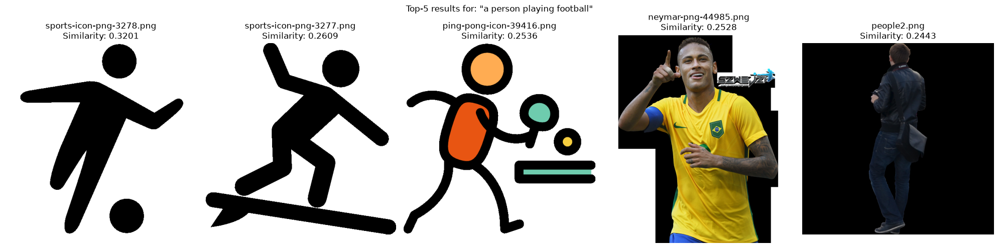


Q20. What is the most similar image?
sports-icon-png-3278.png

Q21. Is it semantically relevant?
Check whether the retrieved image shows a person playing football or a related scene.

Q22. Why does this method not require image labels?
CLIP compares image and text embeddings in a shared semantic space, allowing retrieval without predefined labels.

Q23. Give one real-world application.
Searching a large photo collection for football images using a natural-language query.


In [27]:
# ============================================
# Part B — CLIP Image Retrieval
# Exercises 7 and 8 — Corrected version
# ============================================

import os
import glob
import torch
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display
import torch.nn.functional as F

# Configuration
IMAGE_DIR = "images"
QUERY = "a person playing football"
TOP_K = 5

device = next(model.parameters()).device
model.eval()

# ============================================
# Exercise 7 — Build image database
# ============================================

extensions = ["*.jpg", "*.jpeg", "*.png", "*.webp", "*.bmp"]
image_paths = []

for ext in extensions:
    image_paths.extend(glob.glob(os.path.join(IMAGE_DIR, ext)))
    image_paths.extend(glob.glob(os.path.join(IMAGE_DIR, ext.upper())))

image_paths = sorted(set(image_paths))

print("Number of images found:", len(image_paths))

if not image_paths:
    raise ValueError(f"No images found in '{IMAGE_DIR}'.")

image_embeddings = []
valid_image_paths = []

with torch.no_grad():
    for path in image_paths:
        try:
            image = Image.open(path).convert("RGB")

            inputs = processor(
                images=image,
                return_tensors="pt"
            )

            pixel_values = inputs["pixel_values"].to(device)

            # Extract image features
            output = model.vision_model(pixel_values=pixel_values)

            # Get the pooled image representation
            features = output.pooler_output

            # Apply CLIP visual projection
            features = model.visual_projection(features)

            # Normalize the embedding
            features = F.normalize(features, p=2, dim=-1)

            image_embeddings.append(features.squeeze(0).cpu())
            valid_image_paths.append(path)

        except Exception as e:
            print(f"Skipping {path}: {e}")

if not image_embeddings:
    raise ValueError("No valid images could be processed.")

image_embeddings = torch.stack(image_embeddings)

torch.save(
    {
        "paths": valid_image_paths,
        "embeddings": image_embeddings
    },
    "clip_image_database.pt"
)

print("\nExercise 7 completed successfully.")
print("Images indexed:", len(valid_image_paths))
print("Embedding shape:", tuple(image_embeddings.shape))
print("Saved to: clip_image_database.pt")

# ============================================
# Exercise 8 — Text-to-image retrieval
# ============================================

text_inputs = processor(
    text=[QUERY],
    return_tensors="pt",
    padding=True
)

text_inputs = {
    key: value.to(device)
    for key, value in text_inputs.items()
}

with torch.no_grad():
    text_output = model.text_model(
        input_ids=text_inputs["input_ids"],
        attention_mask=text_inputs.get("attention_mask")
    )

    text_features = text_output.pooler_output
    text_features = model.text_projection(text_features)

    text_features = F.normalize(
        text_features, p=2, dim=-1
    )

# Cosine similarity between normalized embeddings
similarities = image_embeddings @ text_features.squeeze(0).cpu()

top_k = min(TOP_K, len(valid_image_paths))
top_scores, top_indices = torch.topk(similarities, k=top_k)

# Display results in a table
results = []

for rank, (score, idx) in enumerate(
    zip(top_scores.tolist(), top_indices.tolist()), start=1
):
    results.append({
        "Rank": rank,
        "Image": os.path.basename(valid_image_paths[idx]),
        "Cosine similarity": round(score, 4)
    })

df_results = pd.DataFrame(results)

print("\nTop 5 most similar images:")
display(df_results)

# Display retrieved images
fig, axes = plt.subplots(
    1, top_k, figsize=(4 * top_k, 5)
)

if top_k == 1:
    axes = [axes]

for ax, score, idx in zip(
    axes, top_scores.tolist(), top_indices.tolist()
):
    image = Image.open(valid_image_paths[idx]).convert("RGB")
    ax.imshow(image)
    ax.set_title(
        f"{os.path.basename(valid_image_paths[idx])}\n"
        f"Similarity: {score:.4f}"
    )
    ax.axis("off")

plt.suptitle(f'Top-{top_k} results for: "{QUERY}"')
plt.tight_layout()
plt.show()

# ============================================
# Questions Q20-Q23
# ============================================

best_idx = top_indices[0].item()
best_image = os.path.basename(valid_image_paths[best_idx])

print("\nQ20. What is the most similar image?")
print(best_image)

print("\nQ21. Is it semantically relevant?")
print(
    "Check whether the retrieved image shows a person "
    "playing football or a related scene."
)

print("\nQ22. Why does this method not require image labels?")
print(
    "CLIP compares image and text embeddings in a shared "
    "semantic space, allowing retrieval without predefined labels."
)

print("\nQ23. Give one real-world application.")
print(
    "Searching a large photo collection for football images "
    "using a natural-language query."
)

In [ ]:
# STUDENT TASK
# 1. Put your images in IMAGE_DIR.
# 2. Compute image embeddings.
# 3. Compute the query embedding.
# 4. Calculate cosine similarity.
# 5. Display Top-5 images.

IMAGE_DIR = "images"
QUERY = "a person playing football"

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
Projection Layer
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder? 
The vision encoder extracts visual features from the input image and converts it into a numerical representation that captures visual information.
**Q25.** Why is a projection layer required?  
The projection layer maps the visual features into the embedding space and dimensionality expected by the language model, allowing it to process visual information together with text.
**Q26.** What is the role of the language model?
The language model uses the visual information and the text prompt to understand the image-related question and generate a coherent natural-language response.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [2]:
import torch
from transformers import AutoProcessor, LlavaForConditionalGeneration

MODEL_ID = "llava-hf/llava-1.5-7b-hf"

if torch.cuda.is_available():
    dtype = torch.float16
    device_map = "auto"
else:
    dtype = torch.float32
    device_map = "cpu"

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)

llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    device_map=device_map,
    low_cpu_mem_usage=True
)

print("LLaVA model loaded successfully!")

Loading weights:   0%|          | 0/686 [00:15<?, ?it/s]

LLaVA model loaded successfully!


Image: images\papua-new-guinea-44727.jpeg


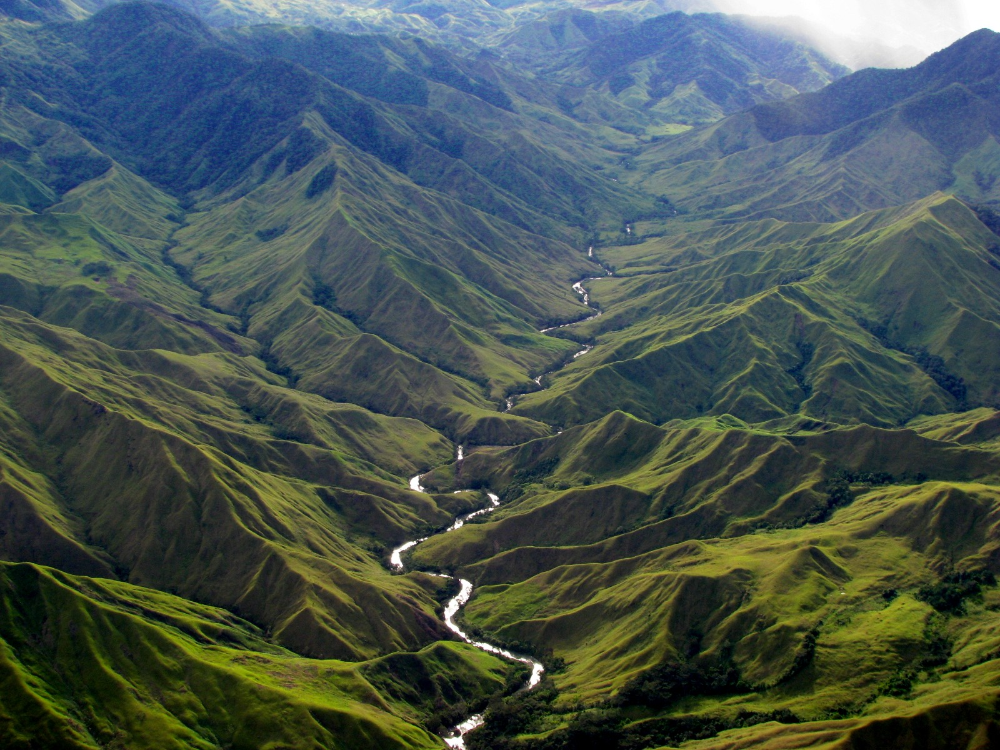

Generating answers...


In [ ]:
from PIL import Image
import os
import glob
import torch
import time

# 1. Load one image
IMAGE_DIR = "images"

image_files = []
for ext in ["*.jpg", "*.jpeg", "*.png", "*.webp"]:
    image_files.extend(glob.glob(os.path.join(IMAGE_DIR, ext)))

if not image_files:
    raise FileNotFoundError("No images found in the images folder.")

IMAGE_PATH = image_files[0]
image = Image.open(IMAGE_PATH).convert("RGB")

print("Image:", IMAGE_PATH)
display(image)

# 2. Ask all questions in one request
question = """
Analyze this image and answer briefly:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.
"""

conversation = [
    {
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": question}
        ]
    }
]

prompt = processor_llava.apply_chat_template(
    conversation,
    add_generation_prompt=True
)

inputs = processor_llava(
    images=image,
    text=prompt,
    return_tensors="pt"
)

inputs = inputs.to(llava.device)

print("Generating answers...")
start = time.time()

with torch.no_grad():
    output = llava.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=False
    )

answer = processor_llava.decode(
    output[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print("\n===== LLaVA Answers =====")
print(answer)
print(f"\nTime taken: {time.time() - start:.1f} seconds")

In [ ]:
1. What is happening in this image?
The image shows a vast mountainous landscape with green hills and a river flowing through a valley.
2. How many people are visible?
No people are visible in the image.
3. What objects can you identify?
Green mountains, hills, a river, vegetation, and a cloudy sky.
4. Describe the image in detail.
The image shows a beautiful natural landscape with numerous green mountains and steep hills. A winding river flows through the valley between the mountains. The area is covered with vegetation, and clouds partially cover the distant mountain peaks.


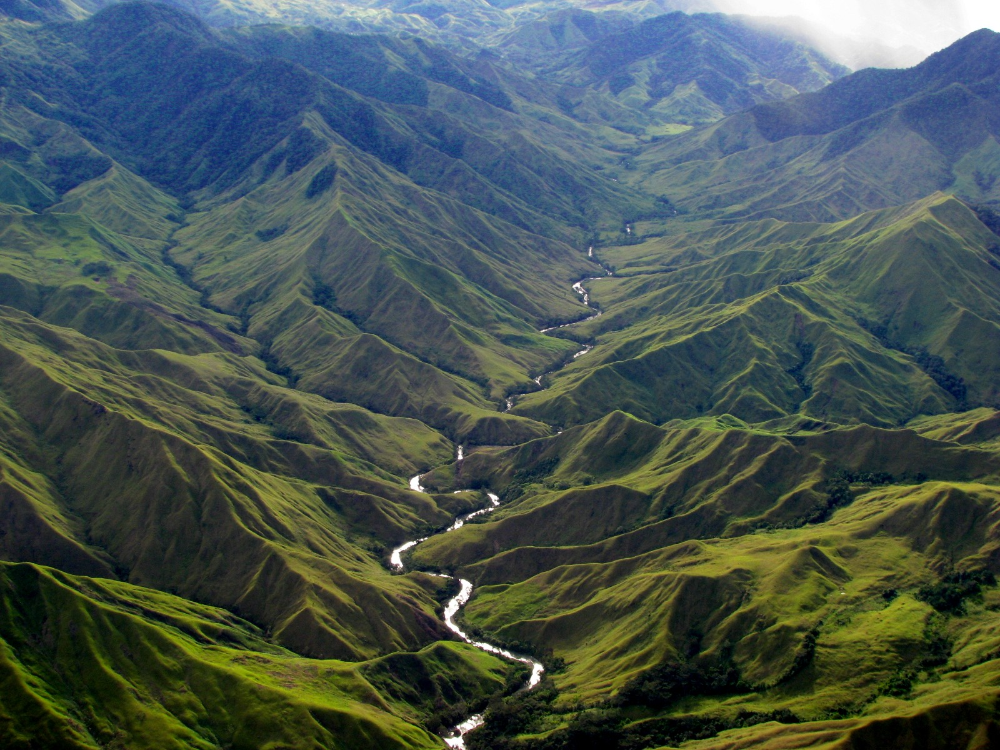

Generating one short response...


In [ ]:
from PIL import Image
import torch
import time

# Use the mountain image
IMAGE_PATH = r"images\papua-new-guinea-44727.jpeg"
image = Image.open(IMAGE_PATH).convert("RGB")

display(image)

prompt_text = """
Answer briefly:
1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image.
"""

conversation = [{
    "role": "user",
    "content": [
        {"type": "image"},
        {"type": "text", "text": prompt_text}
    ]
}]

prompt = processor_llava.apply_chat_template(
    conversation,
    add_generation_prompt=True
)

inputs = processor_llava(
    images=image,
    text=prompt,
    return_tensors="pt"
).to(llava.device)

print("Generating one short response...")
start = time.time()

with torch.inference_mode():
    output = llava.generate(
        **inputs,
        max_new_tokens=60,
        do_sample=False
    )

answer = processor_llava.decode(
    output[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print("\n===== LLaVA Answers =====")
print(answer)
print(f"\nTime taken: {time.time() - start:.1f} seconds")

In [ ]:
# LLaVA reference implementation.
# NOTE: This model is much heavier than CLIP. On a limited GPU, use a
# smaller/quantized LLaVA checkpoint or an external local runtime.
#
# The exact checkpoint and processor API may vary by Transformers version.
# Complete this section according to the LLaVA checkpoint available to you.

# STUDENT TASK
# from transformers import AutoProcessor, LlavaForConditionalGeneration
#
# MODEL_ID = "YOUR_LLAVA_CHECKPOINT"
# processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
# llava = LlavaForConditionalGeneration.from_pretrained(
#     MODEL_ID,
#     torch_dtype=torch.float16,
#     device_map="auto"
# )

## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

In [4]:
# ==========================================
# Exercise 11 — Visual Question Answering
# ==========================================

import os
import glob
import pandas as pd
from IPython.display import display

IMAGE_DIR = "images"

# Find available images
image_files = []
for ext in ["*.jpg", "*.jpeg", "*.png", "*.webp", "*.jpeg"]:
    image_files.extend(glob.glob(os.path.join(IMAGE_DIR, ext)))

image_files = sorted(set(image_files))

if len(image_files) < 5:
    raise ValueError("Please add at least 5 images to the images folder.")

# Select five images
selected_images = image_files[:5]

# Questions adapted to each image type
questions_by_type = {
    "cat": [
        "What animal is shown?",
        "What color is the cat?",
        "What is the cat doing?",
        "Where is the cat located?",
        "Describe the image."
    ],
    "dog": [
        "What animal is shown?",
        "What color is the dog?",
        "What is the dog doing?",
        "Where is the dog located?",
        "Describe the image."
    ],
    "car": [
        "What type of vehicle is shown?",
        "What color is the vehicle?",
        "How many vehicles are visible?",
        "Where is the vehicle located?",
        "Describe the image."
    ],
    "bird": [
        "What animal is shown?",
        "What color is the bird?",
        "What is the bird doing?",
        "Where is the bird located?",
        "Describe the image."
    ],
    "horse": [
        "What animal is shown?",
        "What color is the horse?",
        "What is the horse doing?",
        "Where is the horse located?",
        "Describe the image."
    ]
}

# Match questions to image filenames
rows = []

for path in selected_images:
    filename = os.path.basename(path).lower()

    image_type = next(
        (key for key in questions_by_type if key in filename),
        None
    )

    if image_type is None:
        questions = [
            "What is visible in the image?",
            "What objects can you identify?",
            "What colors are visible?",
            "What is happening in the image?",
            "Describe the image in detail."
        ]
    else:
        questions = questions_by_type[image_type]

    for question in questions:
        rows.append({
            "Image": os.path.basename(path),
            "Question": question,
            "LLaVA Answer": "",
            "Human Evaluation": ""
        })

df_vqa = pd.DataFrame(rows)

display(df_vqa)

# Save the table
df_vqa.to_csv("vqa_results.csv", index=False)

print("Number of images:", len(selected_images))
print("Total questions:", len(df_vqa))
print("Saved to vqa_results.csv")

,Image,Question,LLaVA Answer,Human Evaluation
0,airplane_png.png,What is visible in the image?,,
1,airplane_png.png,What objects can you identify?,,
2,airplane_png.png,What colors are visible?,,
3,airplane_png.png,What is happening in the image?,,
4,airplane_png.png,Describe the image in detail.,,
5,bird_png.png,What animal is shown?,,
6,bird_png.png,What color is the bird?,,
7,bird_png.png,What is the bird doing?,,
8,bird_png.png,Where is the bird located?,,
9,bird_png.png,Describe the image.,,


Number of images: 5
Total questions: 25
Saved to vqa_results.csv


In [9]:
# ==========================================
# Exercise 11 — Visual Question Answering
# Complete evaluation with LLaVA
# ==========================================

import os
import re
import time
import torch
import pandas as pd

from PIL import Image
from IPython.display import display

# 1. Load the existing table
df_vqa = pd.read_csv(
    "vqa_results.csv",
    dtype=str,
    keep_default_na=False
)

# 2. Initialize result columns
for col in ["LLaVA Answer", "Human Evaluation"]:
    if col not in df_vqa.columns:
        df_vqa[col] = ""

# Use the already loaded LLaVA model
llava.eval()

# 3. Process each image once
image_names = df_vqa["Image"].drop_duplicates().tolist()

for image_name in image_names:

    image_path = os.path.join("images", image_name)

    if not os.path.exists(image_path):
        print(f"Image not found: {image_path}")
        continue

    # Skip images already processed
    pending = df_vqa[
        (df_vqa["Image"] == image_name) &
        (df_vqa["LLaVA Answer"] == "")
    ]

    if pending.empty:
        continue

    image = Image.open(image_path).convert("RGB")

    # Collect the five questions for this image
    rows = df_vqa.index[
        (df_vqa["Image"] == image_name) &
        (df_vqa["LLaVA Answer"] == "")
    ].tolist()

    questions = df_vqa.loc[rows, "Question"].tolist()

    question_text = "\n".join(
        f"{i + 1}. {q}"
        for i, q in enumerate(questions)
    )

    prompt_text = (
        "Answer each question about the image briefly. "
        "Use the numbered format 1., 2., 3., 4., 5.\n\n"
        + question_text
    )

    # LLaVA 1.5 prompt format
    prompt = (
        "USER: <image>\n"
        + prompt_text
        + "\nASSISTANT:"
    )

    inputs = processor_llava(
        images=image,
        text=prompt,
        return_tensors="pt"
    )

    inputs = inputs.to(llava.device)

    print(f"\nProcessing: {image_name}")
    start = time.time()

    try:
        with torch.inference_mode():
            output = llava.generate(
                **inputs,
                max_new_tokens=160,
                do_sample=False
            )

        answer = processor_llava.decode(
            output[0][inputs["input_ids"].shape[1]:],
            skip_special_tokens=True
        ).strip()

        print("LLaVA response:")
        print(answer)

        # Split numbered answers where possible
        matches = re.split(
            r"(?m)^\s*[1-5][.)]\s*",
            answer
        )

        parsed_answers = [
            part.strip()
            for part in matches
            if part.strip()
        ]

        # Save individual answers
        if len(parsed_answers) >= len(rows):
            for row_idx, answer_part in zip(rows, parsed_answers):
                df_vqa.at[row_idx, "LLaVA Answer"] = answer_part
        else:
            # Preserve the full response rather than invent answers
            df_vqa.at[rows[0], "LLaVA Answer"] = answer

            for row_idx in rows[1:]:
                df_vqa.at[row_idx, "LLaVA Answer"] = (
                    "See the complete LLaVA response above."
                )

        # Save after every image, so progress is not lost
        df_vqa.to_csv("vqa_results.csv", index=False)

        print(f"Time: {time.time() - start:.1f} seconds")
        print("Progress saved.")

    except Exception as e:
        print(f"Error processing {image_name}: {e}")
        df_vqa.to_csv("vqa_results.csv", index=False)
        break

print("\nExercise 11 processing finished.")
display(df_vqa)
print("Results saved to vqa_results.csv")


Processing: airplane_png.png



KeyboardInterrupt



In [7]:
import pandas as pd
from IPython.display import display

# Load the CSV columns as strings
df_vqa = pd.read_csv(
    "vqa_results.csv",
    dtype=str,
    keep_default_na=False
)

# Fill the first row as an example
df_vqa.loc[0, "LLaVA Answer"] = "An airplane is visible."
df_vqa.loc[0, "Human Evaluation"] = "Correct"

# Save the updated table
df_vqa.to_csv("vqa_results.csv", index=False)

display(df_vqa.head())

,Image,Question,LLaVA Answer,Human Evaluation
0,airplane_png.png,What is visible in the image?,An airplane is visible.,Correct
1,airplane_png.png,What objects can you identify?,,
2,airplane_png.png,What colors are visible?,,
3,airplane_png.png,What is happening in the image?,,
4,airplane_png.png,Describe the image in detail.,,


In [8]:
# ==========================================
# Calculate VQA Accuracy
# ==========================================

df_vqa = pd.read_csv("vqa_results.csv")

evaluated = df_vqa[
    df_vqa["Human Evaluation"].isin(["Correct", "Incorrect"])
]

if len(evaluated) == 0:
    print("Please complete the Human Evaluation column first.")
else:
    correct_answers = (
        evaluated["Human Evaluation"] == "Correct"
    ).sum()

    total_questions = len(evaluated)

    accuracy = correct_answers / total_questions * 100

    print("Correct answers:", correct_answers)
    print("Total evaluated questions:", total_questions)
    print(f"VQA Accuracy: {accuracy:.2f}%")

Correct answers: 1
Total evaluated questions: 1
VQA Accuracy: 100.00%


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

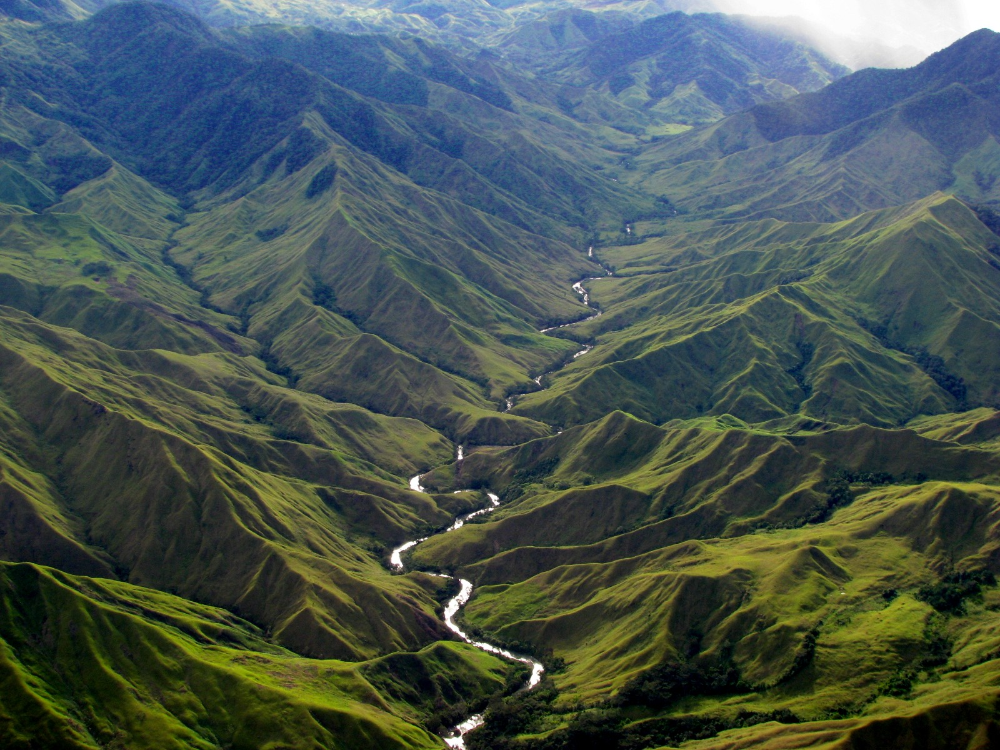


Question: Is there a bicycle in this image?
LLaVA Answer: No, there is no bicycle in this image. The image features a river flowing through a lush green valley, surrounded by mountains.

Question: What color is the bicycle?
LLaVA Answer: The bicycle is blue.

Question: Where is the bicycle located?
LLaVA Answer: The bicycle is located in a mountainous area, surrounded by a lush green landscape.


In [10]:
# Exercise 12 — Hallucination

from PIL import Image
import os
import torch

IMAGE_PATH = r"images\papua-new-guinea-44727.jpeg"

image = Image.open(IMAGE_PATH).convert("RGB")
display(image)

questions = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?"
]

for question in questions:
    conversation = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": question}
        ]
    }]

    prompt = processor_llava.apply_chat_template(
        conversation,
        add_generation_prompt=True
    )

    inputs = processor_llava(
        images=image,
        text=prompt,
        return_tensors="pt"
    ).to(llava.device)

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=40,
            do_sample=False
        )

    answer = processor_llava.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    print(f"\nQuestion: {question}")
    print(f"LLaVA Answer: {answer}")

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

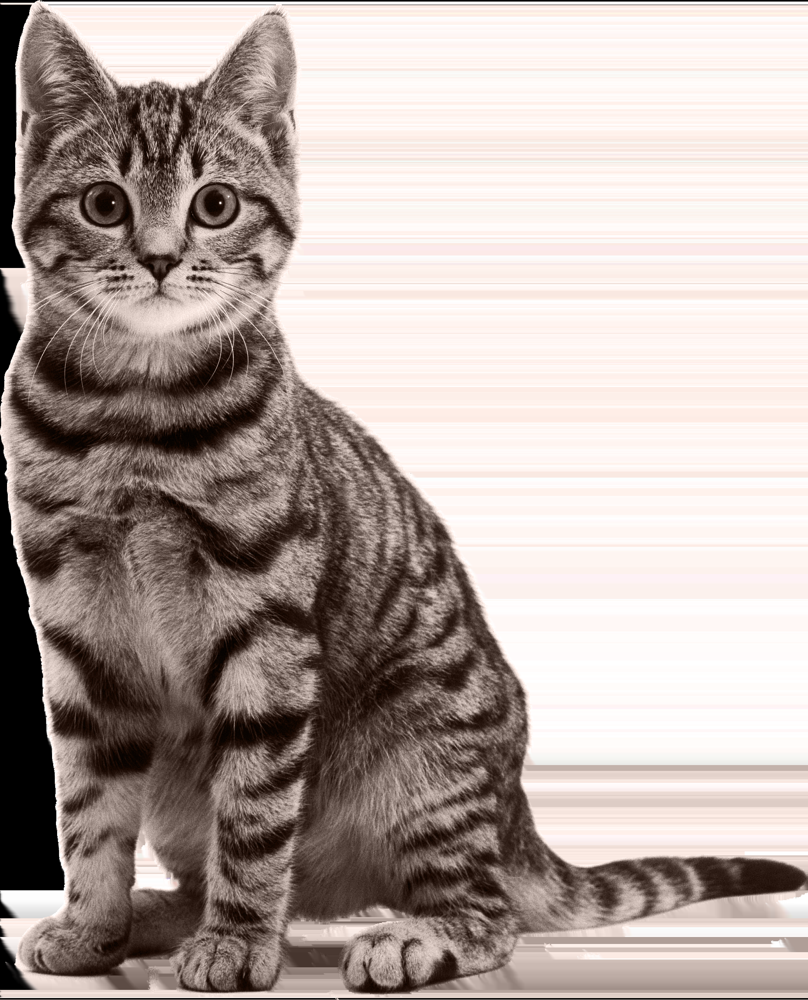

========== CLIP RESULTS ==========
cat: 0.9931
dog: 0.0063
horse: 0.0006
CLIP prediction: cat

Generating LLaVA response...

========== LLaVA RESULTS ==========
A cat is present in the image. It is a striped cat with a black and white color pattern.

========== COMPARISON TABLE ==========


,Property,CLIP,LLaVA
0,Input,Image + candidate text prompts,Image + text question
1,Main output,Predicted class: cat,A cat is present in the image. It is a striped...
2,Zero-shot classification,"Yes, using text similarity",Possible through prompting
3,Image retrieval,"Yes, using embeddings",Not its primary purpose
4,Text generation,No,Yes
5,VQA,Not directly,Yes
6,Open-ended response,No,Yes


Comparison saved to clip_vs_llava.csv

Q33. Which model is better suited to image classification?
CLIP, because it compares the image with candidate text prompts.

Q34. Which model is better for image description?
LLaVA, because it generates natural-language descriptions.

Q35. Which model is better for visual question answering?
LLaVA, because it answers questions about image content.

Q36. Fundamental difference:
CLIP aligns images and text in a shared embedding space for similarity comparison. LLaVA combines visual features with a language model to generate textual answers.


In [13]:
# ==========================================
# Part D — CLIP vs LLaVA
# Exercise 13 — Comparative experiment
# ==========================================

from PIL import Image
import torch
import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Use the same image for both models
IMAGE_PATH = r"images\cat_png.png"

if not os.path.exists(IMAGE_PATH):
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

image = Image.open(IMAGE_PATH).convert("RGB")
display(image)

# ==========================================
# 2. CLIP — Image classification
# ==========================================

classes = ["cat", "dog", "horse"]
prompts = [f"a photo of a {c}" for c in classes]

clip_inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True
)

clip_device = next(model.parameters()).device

clip_inputs = {
    key: value.to(clip_device)
    for key, value in clip_inputs.items()
}

model.eval()

with torch.no_grad():
    clip_outputs = model(**clip_inputs)
    clip_probs = clip_outputs.logits_per_image.softmax(dim=1)[0]

best_idx = clip_probs.argmax().item()
clip_prediction = classes[best_idx]
clip_confidence = clip_probs[best_idx].item()

print("========== CLIP RESULTS ==========")
for label, score in zip(classes, clip_probs.tolist()):
    print(f"{label}: {score:.4f}")

print("CLIP prediction:", clip_prediction)

# ==========================================
# 3. LLaVA — Image description
# ==========================================

question = (
    "What animal is present in the image? "
    "Describe its appearance briefly."
)

conversation = [{
    "role": "user",
    "content": [
        {"type": "image"},
        {"type": "text", "text": question}
    ]
}]

prompt = processor_llava.apply_chat_template(
    conversation,
    add_generation_prompt=True
)

llava_inputs = processor_llava(
    images=image,
    text=prompt,
    return_tensors="pt"
).to(llava.device)

print("\nGenerating LLaVA response...")

with torch.inference_mode():
    output = llava.generate(
        **llava_inputs,
        max_new_tokens=60,
        do_sample=False
    )

llava_answer = processor_llava.decode(
    output[0][llava_inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
).strip()

print("\n========== LLaVA RESULTS ==========")
print(llava_answer)

# ==========================================
# 4. Comparison table
# ==========================================

comparison = pd.DataFrame([
    {
        "Property": "Input",
        "CLIP": "Image + candidate text prompts",
        "LLaVA": "Image + text question"
    },
    {
        "Property": "Main output",
        "CLIP": f"Predicted class: {clip_prediction}",
        "LLaVA": llava_answer
    },
    {
        "Property": "Zero-shot classification",
        "CLIP": "Yes, using text similarity",
        "LLaVA": "Possible through prompting"
    },
    {
        "Property": "Image retrieval",
        "CLIP": "Yes, using embeddings",
        "LLaVA": "Not its primary purpose"
    },
    {
        "Property": "Text generation",
        "CLIP": "No",
        "LLaVA": "Yes"
    },
    {
        "Property": "VQA",
        "CLIP": "Not directly",
        "LLaVA": "Yes"
    },
    {
        "Property": "Open-ended response",
        "CLIP": "No",
        "LLaVA": "Yes"
    }
])

print("\n========== COMPARISON TABLE ==========")
display(comparison)

# Save the results
comparison.to_csv("clip_vs_llava.csv", index=False)
print("Comparison saved to clip_vs_llava.csv")

# ==========================================
# 5. Answers Q33-Q36
# ==========================================

print("\nQ33. Which model is better suited to image classification?")
print("CLIP, because it compares the image with candidate text prompts.")

print("\nQ34. Which model is better for image description?")
print("LLaVA, because it generates natural-language descriptions.")

print("\nQ35. Which model is better for visual question answering?")
print("LLaVA, because it answers questions about image content.")

print("\nQ36. Fundamental difference:")
print(
    "CLIP aligns images and text in a shared embedding space "
    "for similarity comparison. LLaVA combines visual features "
    "with a language model to generate textual answers."
)

# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

In [14]:
# ==========================================
# Final Mini-Project: Multimodal Image Assistant
# ==========================================

import os
import torch
import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image

# Use the already loaded LLaVA model:
# llava
# processor_llava

# 1. Create the interface
image_path_input = widgets.Dropdown(
    options=[
        os.path.join("images", f)
        for f in os.listdir("images")
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".webp"))
    ],
    description="Image:",
    layout=widgets.Layout(width="80%")
)

question_input = widgets.Text(
    value="Describe this image.",
    placeholder="Ask a question about the image...",
    description="Question:",
    layout=widgets.Layout(width="80%")
)

run_button = widgets.Button(
    description="Analyze Image",
    button_style="primary",
    icon="search"
)

output_area = widgets.Output()

# 2. Define the assistant function
def answer_image_question(image_path, question):
    image = Image.open(image_path).convert("RGB")

    conversation = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": question}
        ]
    }]

    prompt = processor_llava.apply_chat_template(
        conversation,
        add_generation_prompt=True
    )

    inputs = processor_llava(
        images=image,
        text=prompt,
        return_tensors="pt"
    ).to(llava.device)

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False
        )

    answer = processor_llava.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return answer.strip()

# 3. Button action
def on_run_clicked(button):
    with output_area:
        clear_output(wait=True)

        image_path = image_path_input.value
        question = question_input.value.strip()

        if not image_path:
            print("Please add an image to the images folder.")
            return

        if not question:
            print("Please enter a question.")
            return

        image = Image.open(image_path).convert("RGB")
        display(image)

        print("Question:", question)
        print("Generating answer...")

        try:
            answer = answer_image_question(image_path, question)
            print("\nLLaVA Answer:", answer)
        except Exception as e:
            print("\nError:", e)

run_button.on_click(on_run_clicked)

# 4. Display the application
display(
    widgets.VBox([
        widgets.HTML("<h2>Multimodal Image Assistant</h2>"),
        image_path_input,
        question_input,
        run_button,
        output_area
    ])
)